In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from mlxtend.plotting import plot_decision_regions
from sklearn.tree import plot_tree

In [ ]:
df = pd.read_csv('../../datasets/Social_Network_Ads.csv')
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [3]:
x = df.iloc[:, :-1]
y = df['Purchased']

x.ndim, y.ndim

(2, 1)

In [4]:
ss = StandardScaler()
ss.fit(x)
# ss.transform(x)

StandardScaler()

In [5]:
x = pd.DataFrame(ss.transform(x), columns=x.columns)
x.head()

,Age,EstimatedSalary
0,-1.781797,-1.490046
1,-0.253587,-1.460681
2,-1.113206,-0.785290
3,-1.017692,-0.374182
4,-1.781797,0.183751


In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [7]:
dt=DecisionTreeClassifier() 
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [8]:
dt.score(x_test, y_test)

0.8375

In [9]:
dt.score(x_train, y_train)

0.996875

As here we can see that the model performs very well on the trained data but not on the test data, means the model us overfitted

**To resolve the model overfitting we do ***pruning*****

---

## Pre Pruning

Using the **max_depth** parameter

In [10]:
dt_pre = DecisionTreeClassifier(max_depth=5) 
dt_pre.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=5)

In [11]:
dt_pre.score(x_test, y_test)*100

90.0

In [12]:
dt_pre.score(x_train, y_train)*100

93.4375

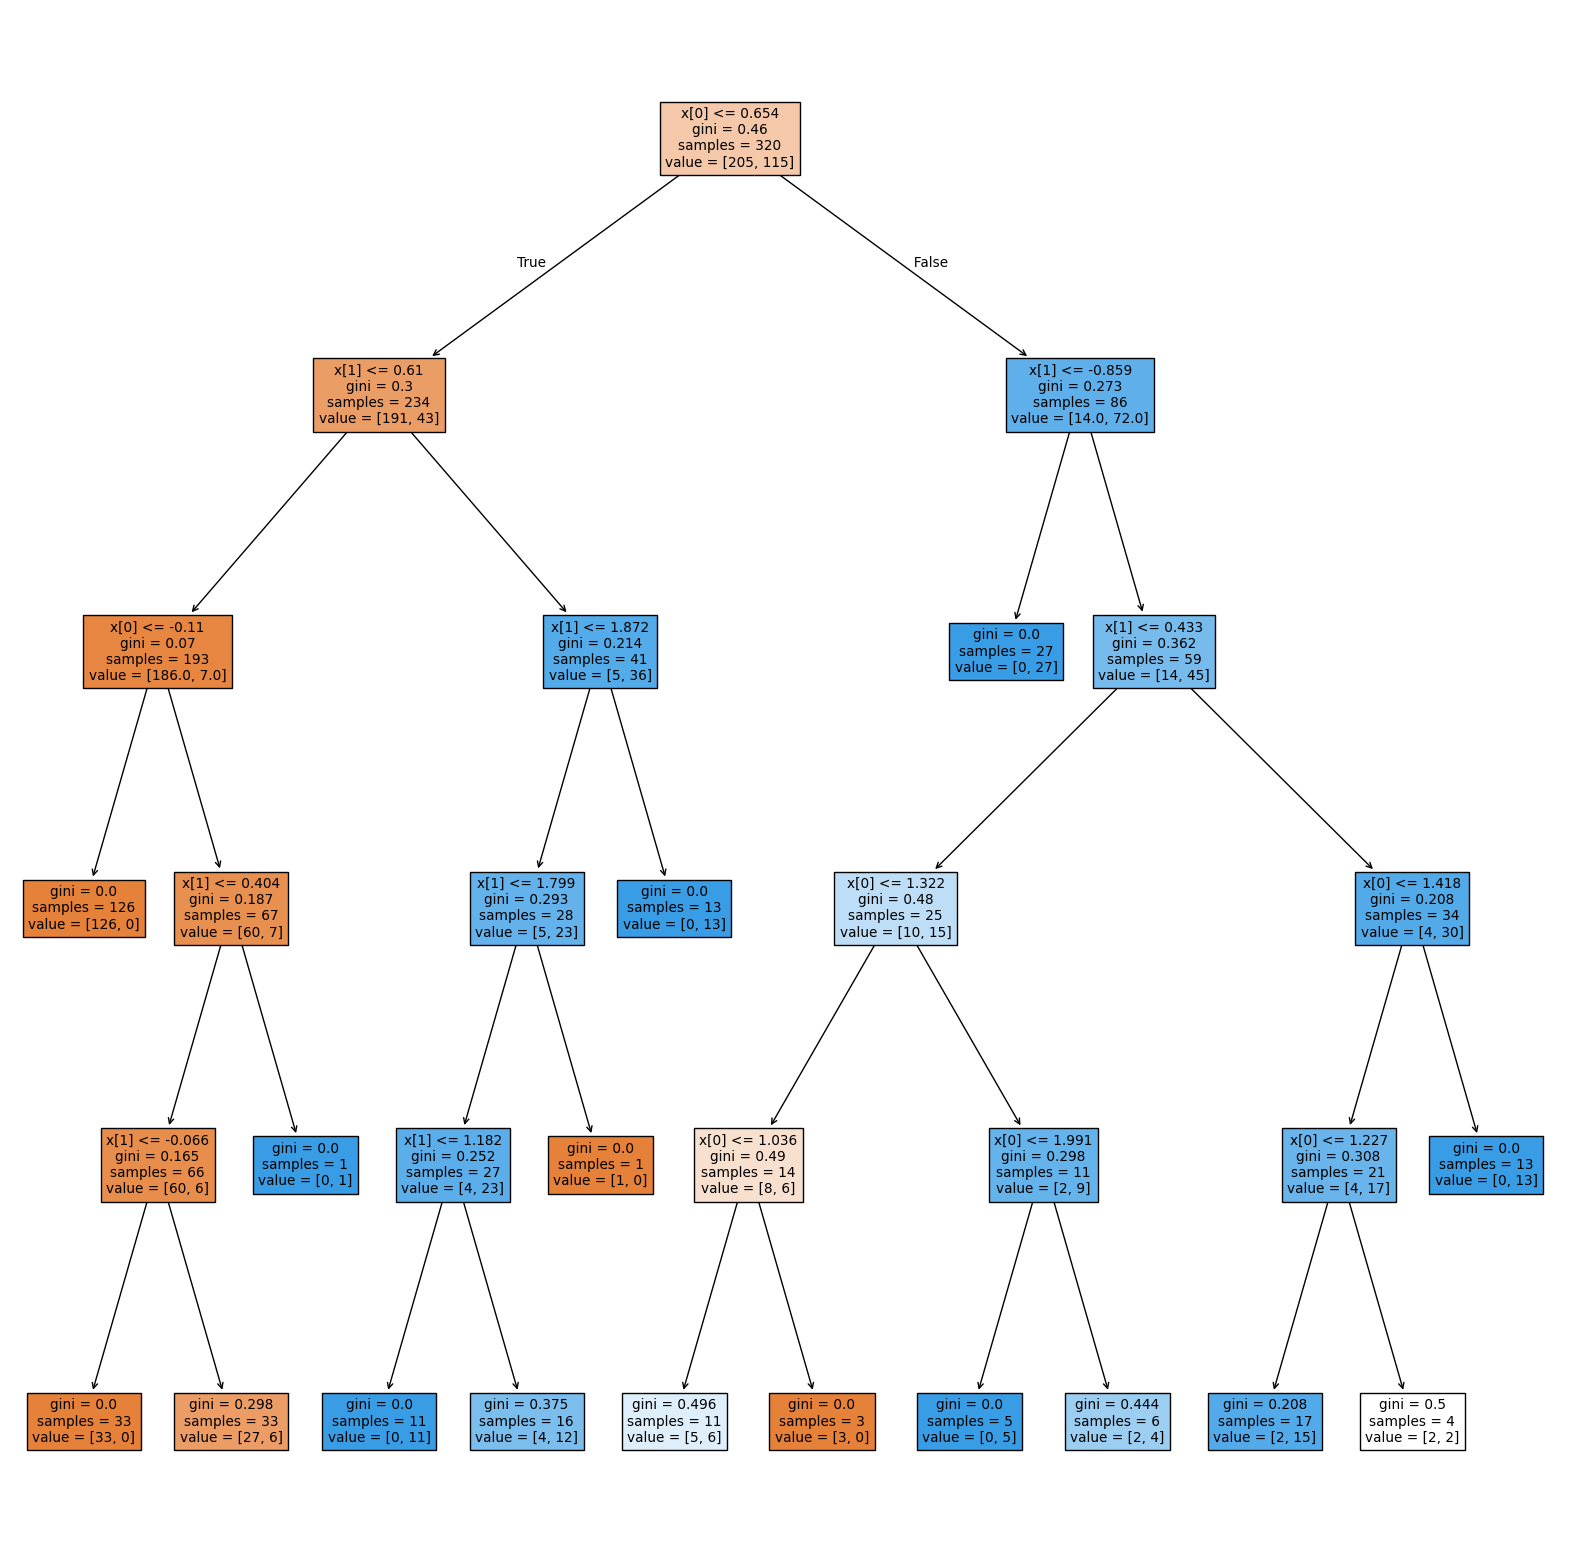

In [13]:
plt.figure(figsize=(20,20))
plot_tree(dt_pre, filled=True)

plt.savefig("./images/pre_pruning.jpg")
plt.show()

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


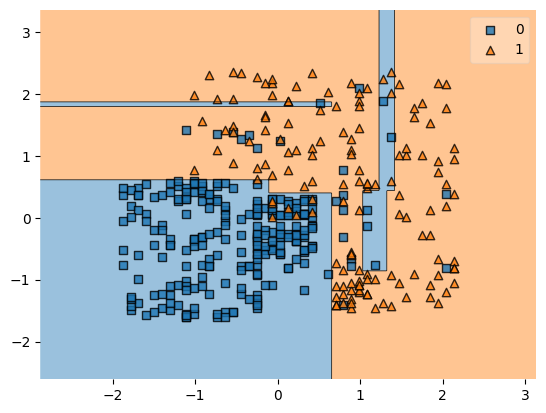

In [14]:
plot_decision_regions(x.to_numpy(), y.to_numpy(), clf=dt_pre)
plt.show()

---

## Post Pruning

In post pruning we change the **max_depth** value continuously and selects the best value

In [15]:
for i in range(1,20):
    dt_post = DecisionTreeClassifier(max_depth=i)
    dt_post.fit(x_train, y_train)

    print(dt_post.score(x_test, y_test), "        ",  dt_post.score(x_train, y_train), "        ", i)

0.9          0.821875          1
0.9125          0.91875          2
0.9125          0.91875          3
0.9125          0.93125          4
0.9          0.934375          5
0.8625          0.95          6
0.85          0.96875          7
0.85          0.975          8
0.85          0.98125          9
0.85          0.984375          10
0.8375          0.990625          11
0.8375          0.990625          12
0.8375          0.996875          13
0.8375          0.996875          14
0.8375          0.996875          15
0.8375          0.996875          16
0.8375          0.996875          17
0.8375          0.996875          18
0.8375          0.996875          19


From above we can see that we get the best values for **max_depth** 2 and 3 , as the difference between accuraccy of model on training and testing data is minimin

In [16]:
dt_post = DecisionTreeClassifier(max_depth=3) 
dt_post.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3)

In [17]:
dt_post.score(x_test, y_test)*100, dt_post.score(x_train, y_train)*100

(91.25, 91.875)

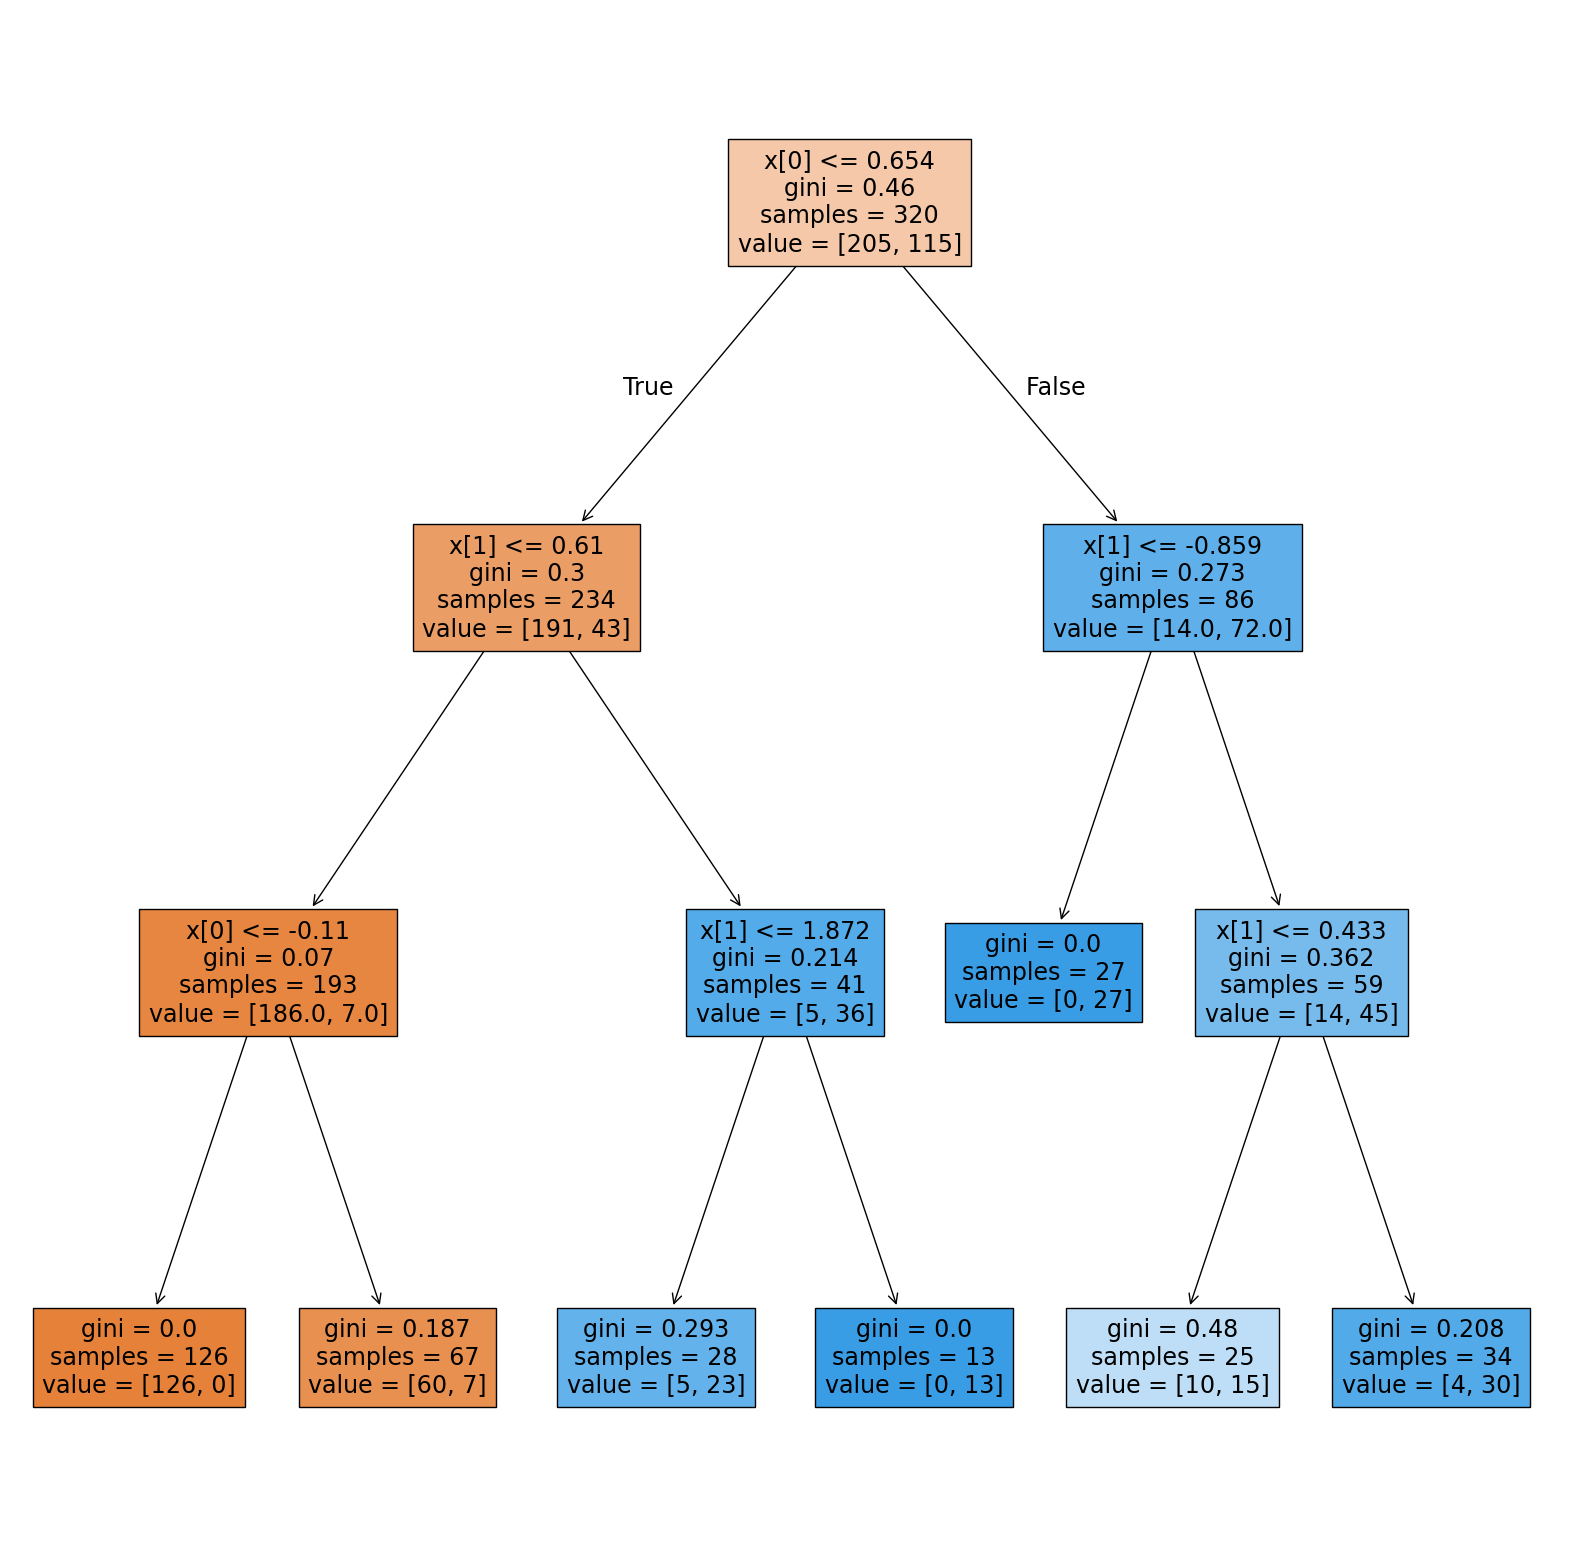

In [18]:
plt.figure(figsize=(20,20))
plot_tree(dt_post, filled=True)

plt.savefig("./images/post_pruning.jpg")
plt.show()

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


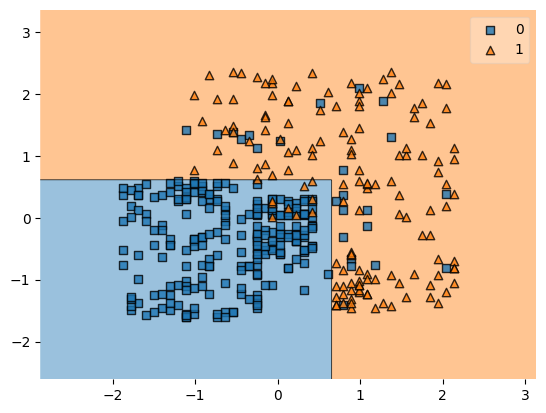

In [19]:
plot_decision_regions(x.to_numpy(), y.to_numpy(), clf=dt_post)
plt.show()

---